# ARIMAX — Previsão do IPCA com variáveis externas defasadas

**Projeto:** IPCA sob pressão externa — análise comparativa entre ARIMAX, Prophet e LightGBM
**Autor:** Gabriel Abreu
**Orientadora:** Bruna Nogueira Rezende

## Fundamentação do modelo

O ARIMAX (Box et al., 2016) estende o ARIMA clássico com variáveis exógenas:

$$\varphi(B)(1-B)^d y_t = \theta(B)\varepsilon_t + \sum_k \beta_k \, x_{k,t-l_k}$$

É a **referência paramétrica linear** para previsão de séries macroeconômicas:
preserva interpretabilidade dos coeficientes (cada β tem leitura econômica direta —
elasticidade do IPCA a choques no câmbio e CPI EUA), oferece inferência clássica
para teste das hipóteses, e tem boa performance em séries com forte componente
autorregressivo como a inflação mensal. Sua limitação é a hipótese de relação
linear e estabilidade paramétrica, o que justifica a comparação com Prophet e
LightGBM.

## Estrutura

1. Caracterização exploratória das séries
2. Transformações e tratamento de dados
3. Testes de estacionariedade (ADF/KPSS) e ACF/PACF
4. Defasagens — confirmação visual da seleção feita em `data_prep`
5. Engenharia de features e prevenção de leakage
6. Estrutura de validação temporal (expanding window)
7. Seleção da ordem ARIMAX (AIC/BIC)
8. Estimação e diagnóstico
9. Avaliação fora da amostra — métricas por horizonte
10. Análise por regime de volatilidade (H2)
11. Diebold-Mariano (H3 — ganho do CPI)
12. Visualizações e exportação


## 0. Dependências

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

import itertools
import pickle

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools         import adfuller, kpss
from statsmodels.graphics.tsaplots     import plot_acf, plot_pacf
from sklearn.metrics                   import mean_absolute_error, mean_squared_error
from scipy                              import stats

np.random.seed(42)
plt.rcParams['figure.dpi']           = 130
plt.rcParams['axes.spines.top']      = False
plt.rcParams['axes.spines.right']    = False

print('Dependências carregadas.')

Dependências carregadas.


## 1. Caracterização exploratória das séries

Atende ao tópico 1 dos resultados preliminares (orientadora):
gráficos temporais, estatísticas descritivas e interpretação econômica.


In [2]:
df = pd.read_csv('../final_df_with_lags.csv', parse_dates=['data'], index_col='data')
df = df.asfreq('MS')

print(f'Shape: {df.shape}')
print(f'Período: {df.index[0].date()} → {df.index[-1].date()}')
print(f'Colunas: {df.columns.tolist()}')
df.head()

Shape: (295, 6)
Período: 2000-06-01 → 2024-12-01
Colunas: ['ipca_pct', 'us_cpi_pct', 'usd_brl_pct', 'us_cpi_lag2', 'us_cpi_lag3', 'usd_brl_lag4']


,ipca_pct,us_cpi_pct,usd_brl_pct,us_cpi_lag2,us_cpi_lag3,usd_brl_lag4
data,,,,,,
2000-06-01,0.23,0.524781,-1.456258,0.058411,0.824499,-1.880826
2000-07-01,1.61,0.232019,-1.400000,0.116754,0.058411,-1.198756
2000-08-01,1.31,0.000000,2.738337,0.524781,0.116754,3.399531
2000-09-01,0.23,0.520833,1.113305,0.232019,0.524781,1.101456
2000-10-01,0.14,0.172712,3.541791,0.000000,0.232019,-1.456258


### 1.1. Estatísticas descritivas das três séries em variação % mensal

In [3]:
series_cols = ['ipca_pct', 'usd_brl_pct', 'us_cpi_pct']

desc = df[series_cols].describe().T
desc['skewness'] = df[series_cols].skew()
desc['kurtosis'] = df[series_cols].kurt()
desc = desc[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness', 'kurtosis']]

print('Estatísticas descritivas — variação % mensal:')
print(desc.round(4).to_string())

print('''
Interpretação econômica:
- IPCA: média positiva (inflação crônica do período), desvio moderado, leve assimetria positiva
  com curtose elevada → presença de choques inflacionários extremos.
- Câmbio USD/BRL: média próxima de zero (sem viés cambial sistemático), mas desvio elevado
  e cauda direita pesada — depreciações abruptas em crises (2002, 2008, 2015-16, 2020).
- CPI EUA: média positiva baixa (inflação americana estável historicamente), desvio reduzido
  vs. câmbio brasileiro, mas curtose alta capturando o choque inflacionário 2021-22.
''')

Estatísticas descritivas — variação % mensal:
             count    mean     std      min     25%     50%     75%      max  skewness  kurtosis
ipca_pct     295.0  0.5049  0.3962  -0.6800  0.2600  0.4600  0.6900   3.0200    1.5592    7.1292
usd_brl_pct  295.0  0.5336  4.9720 -13.8171 -2.5276 -0.0494  3.2173  28.8721    1.1230    4.5366
us_cpi_pct   295.0  0.2077  0.3838  -1.9153 -0.0102  0.2012  0.4581   1.3736   -0.5441    3.3124

Interpretação econômica:
- IPCA: média positiva (inflação crônica do período), desvio moderado, leve assimetria positiva
  com curtose elevada → presença de choques inflacionários extremos.
- Câmbio USD/BRL: média próxima de zero (sem viés cambial sistemático), mas desvio elevado
  e cauda direita pesada — depreciações abruptas em crises (2002, 2008, 2015-16, 2020).
- CPI EUA: média positiva baixa (inflação americana estável historicamente), desvio reduzido
  vs. câmbio brasileiro, mas curtose alta capturando o choque inflacionário 2021-22.



### 1.2. Estatísticas descritivas por subperíodo (pré e pós-2020)

In [4]:
pre = df[df.index <  '2020-01-01'][series_cols]
pos = df[df.index >= '2020-01-01'][series_cols]

comp = pd.DataFrame({
    'media_pre':  pre.mean(),
    'media_pos':  pos.mean(),
    'desvio_pre': pre.std(),
    'desvio_pos': pos.std(),
})
comp['delta_media']  = comp['media_pos']  - comp['media_pre']
comp['ratio_desvio'] = comp['desvio_pos'] / comp['desvio_pre']

print('Pré (jan/2000–dez/2019) vs Pós-2020:')
print(comp.round(4).to_string())

print('''
→ Volatilidade pós-2020 é substancialmente maior nas três séries, com aumento mais
  acentuado no câmbio. Isso justifica o desenho de análise condicional por regime
  de volatilidade (H2).
''')

Pré (jan/2000–dez/2019) vs Pós-2020:
             media_pre  media_pos  desvio_pre  desvio_pos  delta_media  ratio_desvio
ipca_pct        0.5104     0.4832      0.3857      0.4376      -0.0273        1.1344
usd_brl_pct     0.4645     0.8044      5.1498      4.2316       0.3399        0.8217
us_cpi_pct      0.1729     0.3439      0.3746      0.3921       0.1709        1.0468

→ Volatilidade pós-2020 é substancialmente maior nas três séries, com aumento mais
  acentuado no câmbio. Isso justifica o desenho de análise condicional por regime
  de volatilidade (H2).



### 1.3. Gráficos temporais com marcação de eventos macroeconômicos

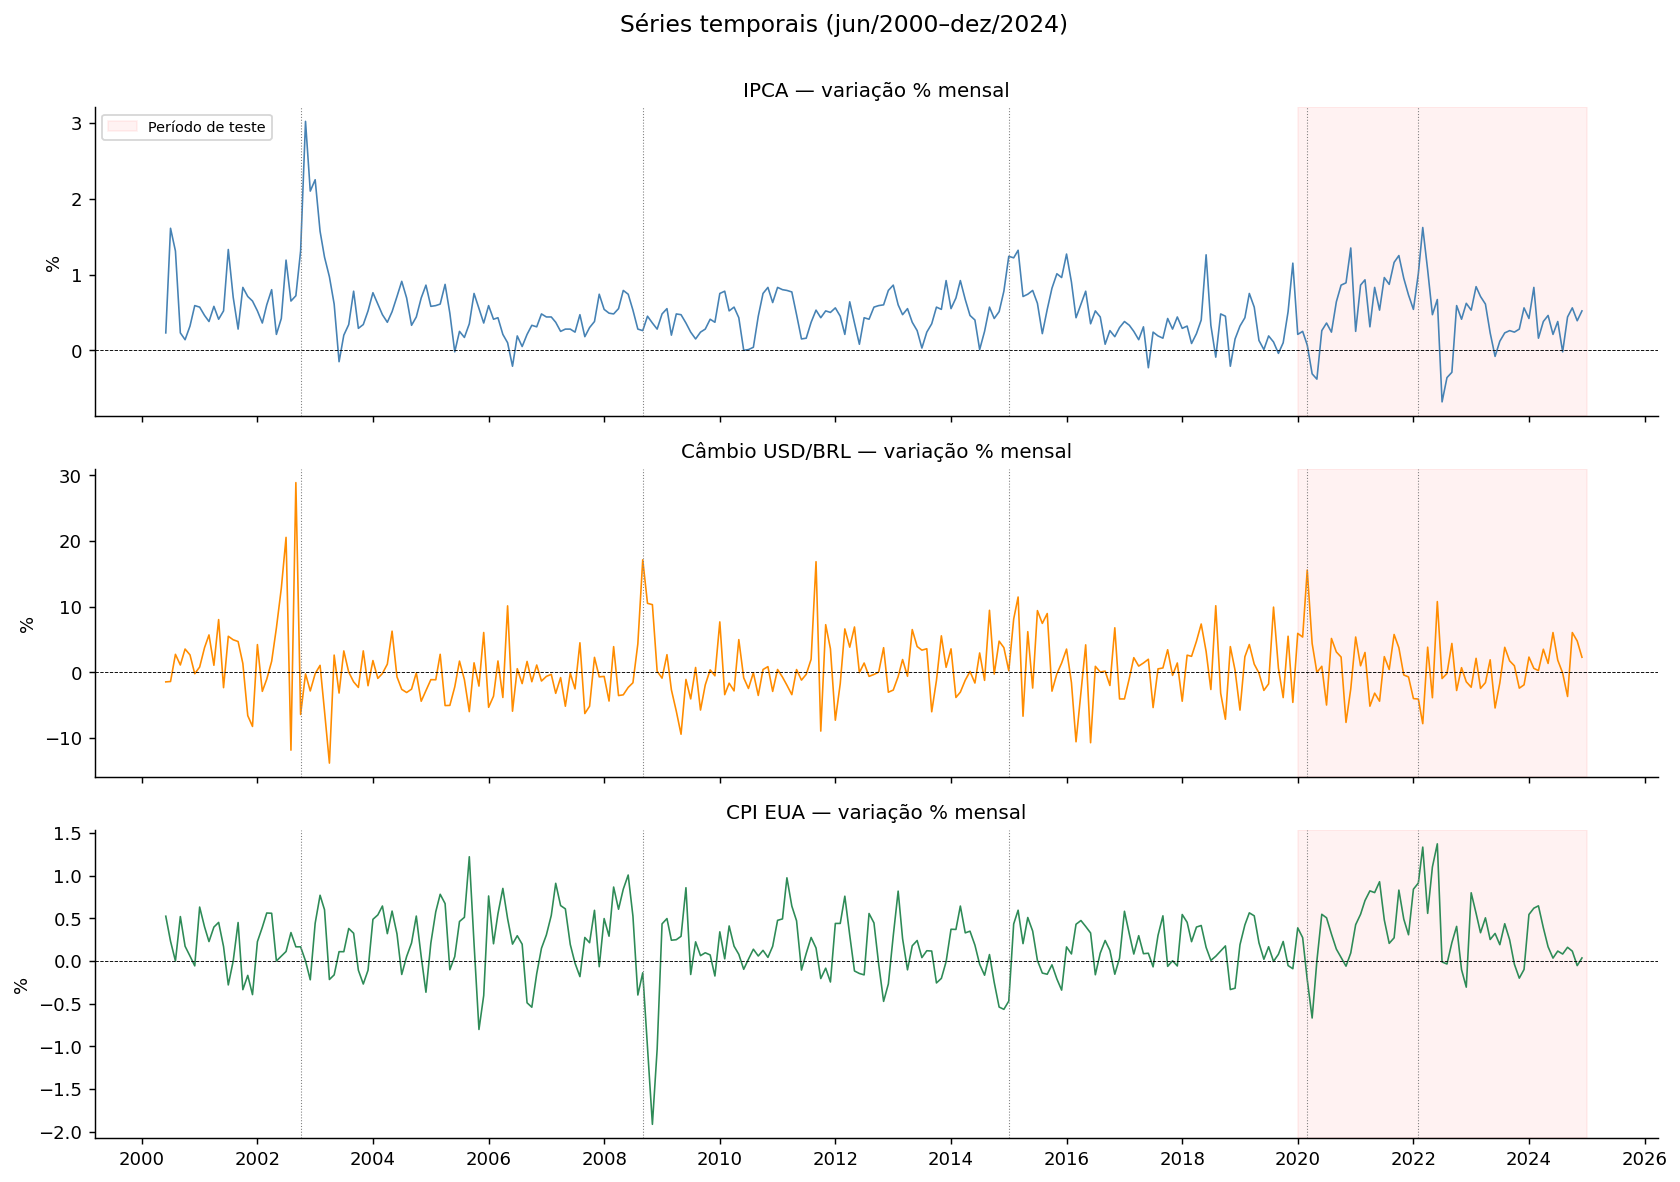


Comportamento pré vs. pós-2020:
- Pré-2020: IPCA oscila entre 0 e 1% com episódios de pico em 2002-03 e 2015-16.
  Câmbio com depreciações pontuais associadas a eventos políticos e crises externas.
  CPI EUA estável, com exceção da deflação de 2009.
- Pós-2020: COVID provoca depreciação cambial abrupta em mar-abr/2020, seguida de
  choque inflacionário global em 2021-22 (commodities + reabertura econômica).
  IPCA registra picos sequenciais em 2021-22 antes de acomodação em 2023-24.



In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

series_info = [
    ('ipca_pct',    'IPCA — variação % mensal',          'steelblue'),
    ('usd_brl_pct', 'Câmbio USD/BRL — variação % mensal', 'darkorange'),
    ('us_cpi_pct',  'CPI EUA — variação % mensal',        'seagreen'),
]

# Eventos macroeconômicos documentados
events = [
    ('2002-10-01', 'Eleição\n2002'),
    ('2008-09-01', 'Crise\nfinanceira'),
    ('2015-01-01', 'Crise\nBR 2015-16'),
    ('2020-03-01', 'COVID-19'),
    ('2022-02-01', 'Choque\nenergia/commodities'),
]

for ax, (col, title, color) in zip(axes, series_info):
    ax.plot(df.index, df[col], color=color, linewidth=0.9)
    ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2024-12-31'),
               alpha=0.05, color='red', label='Período de teste')
    for ev_date, ev_label in events:
        ax.axvline(pd.Timestamp(ev_date), color='gray', linewidth=0.6, linestyle=':')
    ax.set_title(title, fontsize=11)
    ax.set_ylabel('%')

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Séries temporais (jun/2000–dez/2024)', fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig('eda_series_temporais.png', dpi=150, bbox_inches='tight')
plt.show()

print('''
Comportamento pré vs. pós-2020:
- Pré-2020: IPCA oscila entre 0 e 1% com episódios de pico em 2002-03 e 2015-16.
  Câmbio com depreciações pontuais associadas a eventos políticos e crises externas.
  CPI EUA estável, com exceção da deflação de 2009.
- Pós-2020: COVID provoca depreciação cambial abrupta em mar-abr/2020, seguida de
  choque inflacionário global em 2021-22 (commodities + reabertura econômica).
  IPCA registra picos sequenciais em 2021-22 antes de acomodação em 2023-24.
''')

## 2. Transformações e preparação dos dados

Atende ao tópico 2 dos resultados preliminares: documentação das transformações,
tratamento de NaNs, identificação de outliers e testes de estacionariedade.


### 2.1. Justificativa das transformações

Todas as séries são utilizadas em **variação percentual simples mensal**:

$$\text{var}\%_t = \frac{X_t - X_{t-1}}{X_{t-1}} \times 100$$

- **IPCA**: já divulgado pelo IBGE neste formato.
- **CPI EUA e câmbio**: originalmente em nível; transformação aplicada no `data_prep`.

**Por que variação % e não log-retorno:**
preserva a escala original do IPCA em pontos percentuais, facilitando a interpretação
direta dos erros MAE e MASE em pp. Log-retorno seria preferível para retornos
financeiros agregados, mas aqui prejudicaria a leitura econômica dos resultados.


### 2.2. Valores ausentes

In [6]:
print('Valores ausentes por coluna:')
print(df.isna().sum())

# Interpolação linear para lacunas isoladas (se houver)
for col in df.columns:
    n = df[col].isna().sum()
    if n > 0:
        df[col] = df[col].interpolate(method='linear')
        print(f'  → {col}: {n} valor(es) interpolado(s)')

Valores ausentes por coluna:
ipca_pct        0
us_cpi_pct      0
usd_brl_pct     0
us_cpi_lag2     0
us_cpi_lag3     0
usd_brl_lag4    0
dtype: int64


### 2.3. Identificação de outliers (> 3·σ da média móvel 12 meses)

In [7]:
for col in series_cols:
    s        = df[col]
    rm       = s.rolling(12).mean()
    rs       = s.rolling(12).std()
    outliers = df[(s - rm).abs() > 3 * rs][[col]]

    if len(outliers) > 0:
        print(f'\n── {col} — {len(outliers)} outlier(s) ──')
        print(outliers.head(15).to_string())
    else:
        print(f'{col}: nenhum outlier detectado')

print('''
→ Outliers identificados correspondem a eventos econômicos documentados (COVID em
  mar/abr 2020, choque cambial 2015-16, deflação americana 2009) e são mantidos
  na amostra. Nenhuma correção por erro de registro foi necessária.
''')

ipca_pct: nenhum outlier detectado

── usd_brl_pct — 1 outlier(s) ──
            usd_brl_pct
data                   
2011-09-01    16.834677
us_cpi_pct: nenhum outlier detectado

→ Outliers identificados correspondem a eventos econômicos documentados (COVID em
  mar/abr 2020, choque cambial 2015-16, deflação americana 2009) e são mantidos
  na amostra. Nenhuma correção por erro de registro foi necessária.



### 2.4. Testes de estacionariedade (ADF e KPSS)

ADF — H₀: existe raiz unitária (série não estacionária); rejeição p<0.05.
KPSS — H₀: série estacionária; não-rejeição p>0.05.
Decisão conjunta: série estacionária se ADF rejeita E KPSS não rejeita.


In [8]:
def test_stationarity(s, name):
    s = s.dropna()
    adf_stat, adf_p, _, _, _, _ = adfuller(s)
    kpss_stat, kpss_p, _, _     = kpss(s, regression='c', nlags='auto')

    adf_ok  = adf_p  < 0.05
    kpss_ok = kpss_p > 0.05
    is_stat = adf_ok and kpss_ok

    status = '✓ ESTACIONÁRIA' if is_stat else '✗ NÃO ESTACIONÁRIA'
    print(f'\n── {name} ── {status}')
    print(f'  ADF:  stat={adf_stat:+.4f}, p={adf_p:.4f} → '
          f'{"rejeita H0 (estacionária)" if adf_ok else "não rejeita H0 (raiz unitária)"}')
    print(f'  KPSS: stat={kpss_stat:+.4f}, p={kpss_p:.4f} → '
          f'{"não rejeita H0 (estacionária)" if kpss_ok else "rejeita H0 (não estacionária)"}')
    return {'series': name, 'adf_p': adf_p, 'kpss_p': kpss_p, 'stationary': is_stat}


stationarity_results = []
for col in series_cols:
    stationarity_results.append(test_stationarity(df[col], col))

stationarity_df = pd.DataFrame(stationarity_results)
print('\n→ Conclusão: como o IPCA está em variação percentual mensal, espera-se')
print('  d = 0 (ARMAX, não ARIMAX). Resultado confirmado acima.')


── ipca_pct ── ✓ ESTACIONÁRIA
  ADF:  stat=-8.2876, p=0.0000 → rejeita H0 (estacionária)
  KPSS: stat=+0.2836, p=0.1000 → não rejeita H0 (estacionária)

── usd_brl_pct ── ✓ ESTACIONÁRIA
  ADF:  stat=-10.2309, p=0.0000 → rejeita H0 (estacionária)
  KPSS: stat=+0.1123, p=0.1000 → não rejeita H0 (estacionária)

── us_cpi_pct ── ✓ ESTACIONÁRIA
  ADF:  stat=-3.3896, p=0.0113 → rejeita H0 (estacionária)
  KPSS: stat=+0.1876, p=0.1000 → não rejeita H0 (estacionária)

→ Conclusão: como o IPCA está em variação percentual mensal, espera-se
  d = 0 (ARMAX, não ARIMAX). Resultado confirmado acima.


/var/folders/g5/xnl69wtd0gn4l9p3q14s7h3c0000gn/T/ipykernel_42641/467859966.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, _     = kpss(s, regression='c', nlags='auto')
/var/folders/g5/xnl69wtd0gn4l9p3q14s7h3c0000gn/T/ipykernel_42641/467859966.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, _     = kpss(s, regression='c', nlags='auto')
/var/folders/g5/xnl69wtd0gn4l9p3q14s7h3c0000gn/T/ipykernel_42641/467859966.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, _     = kpss(s, regression='c', nlags='auto')


### 2.5. ACF e PACF do IPCA — identificação de p e q

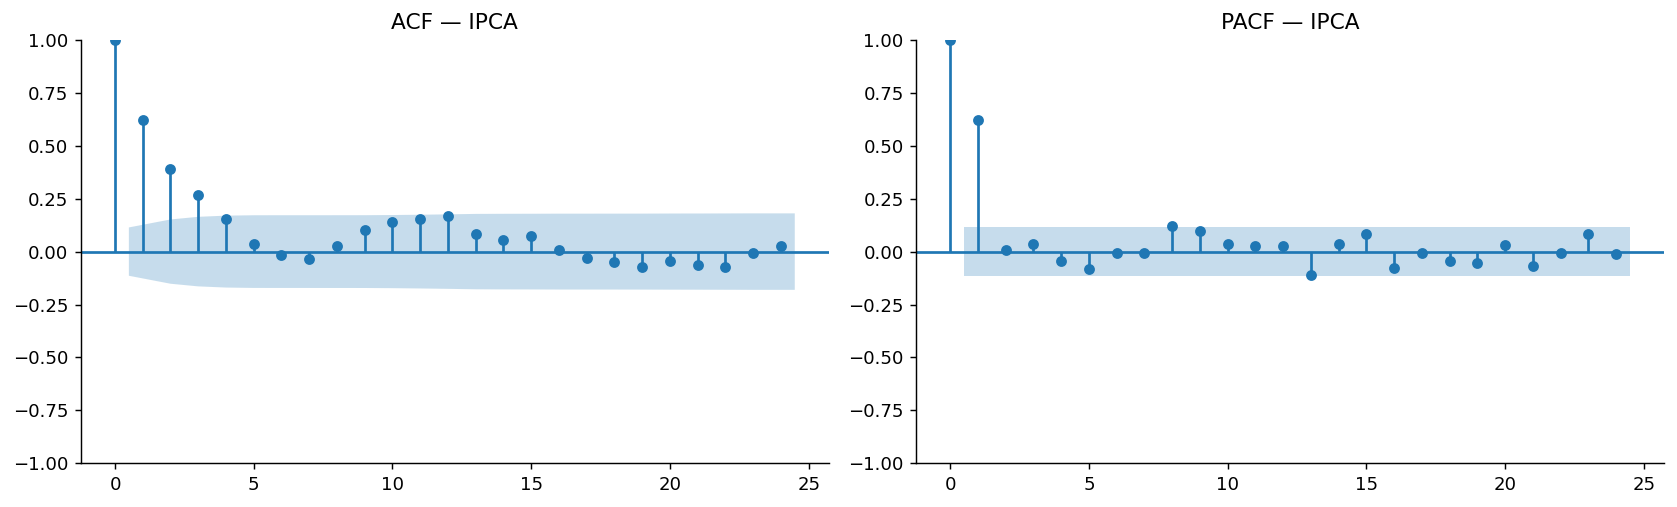


→ ACF: decaimento gradual sugere componente AR.
→ PACF: cortes nos primeiros lags sugerem p baixo (1-2).
→ Confirmação final via busca em grade AIC/BIC na seção 7.



In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf( df['ipca_pct'].dropna(), lags=24, ax=axes[0])
plot_pacf(df['ipca_pct'].dropna(), lags=24, ax=axes[1], method='ywm')
axes[0].set_title('ACF — IPCA')
axes[1].set_title('PACF — IPCA')
plt.tight_layout()
plt.savefig('acf_pacf_ipca.png', dpi=150, bbox_inches='tight')
plt.show()

print('''
→ ACF: decaimento gradual sugere componente AR.
→ PACF: cortes nos primeiros lags sugerem p baixo (1-2).
→ Confirmação final via busca em grade AIC/BIC na seção 7.
''')

## 3. Análise de defasagens e relações entre variáveis

Atende ao tópico 3 dos resultados preliminares.
A seleção da defasagem ótima foi conduzida em `data_prep.ipynb` por CCF + AIC/BIC.
Esta seção confirma visualmente sobre a janela de treino e documenta a justificativa
econômica.


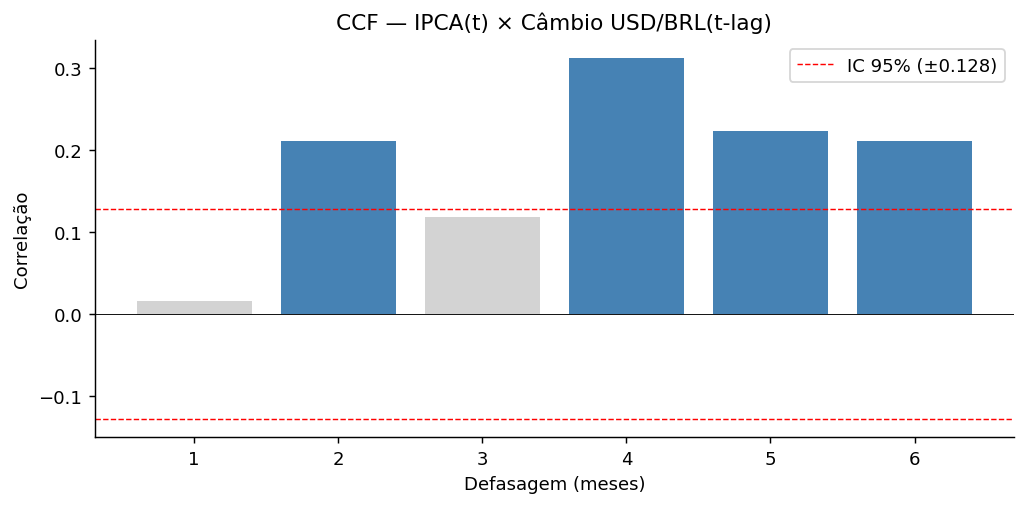

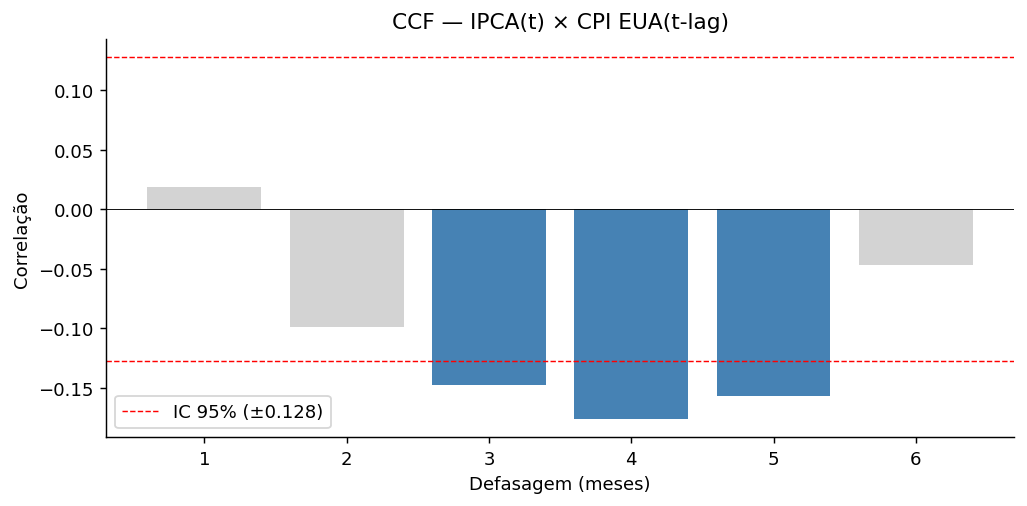


Câmbio — lags significativos (p<0.05):
 lag  correlation  p_value  significant  ci_bound
   2       0.2104   0.0012         True    0.1279
   4       0.3113   0.0000         True    0.1279
   5       0.2230   0.0007         True    0.1279
   6       0.2107   0.0013         True    0.1279

CPI EUA — lags significativos (p<0.05):
 lag  correlation  p_value  significant  ci_bound
   3      -0.1477   0.0245         True    0.1279
   4      -0.1765   0.0072         True    0.1279
   5      -0.1574   0.0169         True    0.1279


In [10]:
def compute_ccf(y, x, max_lag=6):
    n          = len(y)
    conf_bound = 1.96 / np.sqrt(n)
    rows = []
    for lag in range(1, max_lag + 1):
        y_aligned = y.iloc[lag:].values
        x_lagged  = x.iloc[:-lag].values
        r, p      = stats.pearsonr(y_aligned, x_lagged)
        rows.append({
            'lag': lag,
            'correlation': r,
            'p_value':     p,
            'significant': p < 0.05,
            'ci_bound':    conf_bound,
        })
    return pd.DataFrame(rows)


def plot_ccf(ccf_df, x_name):
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['steelblue' if sig else 'lightgray' for sig in ccf_df['significant']]
    ci     = ccf_df['ci_bound'].iloc[0]
    ax.bar(ccf_df['lag'], ccf_df['correlation'], color=colors)
    ax.axhline( ci, color='red', linestyle='--', linewidth=0.8, label=f'IC 95% (±{ci:.3f})')
    ax.axhline(-ci, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0,   color='black', linewidth=0.5)
    ax.set_xlabel('Defasagem (meses)')
    ax.set_ylabel('Correlação')
    ax.set_title(f'CCF — IPCA(t) × {x_name}(t-lag)')
    ax.legend()
    plt.tight_layout()
    plt.savefig(f'ccf_arimax_{x_name.lower().replace(" ", "_").replace("/", "")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()


# CCF calculada apenas sobre janela de treino (evita contaminação)
train_eda = df[df.index < '2020-01-01']

ccf_cambio = compute_ccf(train_eda['ipca_pct'], train_eda['usd_brl_pct'])
ccf_cpi    = compute_ccf(train_eda['ipca_pct'], train_eda['us_cpi_pct'])

plot_ccf(ccf_cambio, 'Câmbio USD/BRL')
plot_ccf(ccf_cpi,    'CPI EUA')

print('\nCâmbio — lags significativos (p<0.05):')
print(ccf_cambio[ccf_cambio['significant']].round(4).to_string(index=False))
print('\nCPI EUA — lags significativos (p<0.05):')
print(ccf_cpi[ccf_cpi['significant']].round(4).to_string(index=False))

### 3.1. Tabela-resumo das defasagens selecionadas e justificativa econômica

| Variável         | Lag escolhido | Método      | Justificativa econômica                                                            |
|------------------|---------------|-------------|------------------------------------------------------------------------------------|
| Câmbio USD/BRL   | 4             | AIC + CCF   | Defasagem média de pass-through cambial para economias emergentes (Belaisch, 2003; Ha et al., 2020): 3-6 meses entre choque cambial e repasse aos preços finais via cadeia de importação. |
| CPI EUA          | 2             | AIC         | Defasagem curta consistente com transmissão via preços de commodities em dólar e expectativas inflacionárias importadas. |
| CPI EUA          | 3             | CCF         | Especificação alternativa avaliada em H3 — captura efeito mais lento via condições de liquidez internacional. |

→ Em caso de divergência entre CCF e AIC/BIC, prevalece o critério de informação (AIC),
  conforme metodologia.


## 4. Construção de variáveis para o ARIMAX e prevenção de leakage

Atende ao tópico 4 dos resultados preliminares.

No ARIMAX, as variáveis exógenas são incorporadas diretamente como `exog`. Toda
defasagem é aplicada no DataFrame antes do treino — a linha do período `t`
contém apenas valores disponíveis até `t-l_k`.

**Especificações estimadas:**
- **M1**: exógenas = `[usd_brl_lag4]` — só câmbio
- **M2**: exógenas = `[usd_brl_lag4, us_cpi_lag2]` — câmbio + CPI (AIC)
- **M2b**: exógenas = `[usd_brl_lag4, us_cpi_lag3]` — câmbio + CPI (CCF), alternativa para H3

Para `h = 2` e `h = 3`, as previsões são geradas pelo método **direto**: cada
horizonte tem seu próprio modelo, com features cuja defasagem mínima é `≥ h`.
Isso elimina propagação de erros entre horizontes (recursivo) e garante ausência
de leakage temporal.


In [11]:
print('''
Esquema de disponibilidade temporal das features (prevenção de leakage):

  Previsão para período t:
    - usd_brl_lag4 disponível em t-4  (sempre usável p/ h=1,2,3,4)
    - us_cpi_lag2  disponível em t-2  (usável p/ h=1,2)
    - us_cpi_lag3  disponível em t-3  (usável p/ h=1,2,3)

  Para h=2 com us_cpi_lag2: feature é o CPI de t-2 — disponível no momento da previsão.
  Para h=3 com us_cpi_lag2: indisponível → usar us_cpi_lag3 ou re-derivar.

→ A defasagem mínima das exógenas (lag 2 do CPI) limita o horizonte máximo direto
  utilizável dessa especificação. Para h=3, usa-se preferencialmente CPI lag 3.
''')


Esquema de disponibilidade temporal das features (prevenção de leakage):

  Previsão para período t:
    - usd_brl_lag4 disponível em t-4  (sempre usável p/ h=1,2,3,4)
    - us_cpi_lag2  disponível em t-2  (usável p/ h=1,2)
    - us_cpi_lag3  disponível em t-3  (usável p/ h=1,2,3)

  Para h=2 com us_cpi_lag2: feature é o CPI de t-2 — disponível no momento da previsão.
  Para h=3 com us_cpi_lag2: indisponível → usar us_cpi_lag3 ou re-derivar.

→ A defasagem mínima das exógenas (lag 2 do CPI) limita o horizonte máximo direto
  utilizável dessa especificação. Para h=3, usa-se preferencialmente CPI lag 3.



## 5. Estrutura de validação temporal

Atende ao tópico 5 dos resultados preliminares.

- **Treino inicial:** jun/2000 – dez/2019 (~234 obs após drop dos NaNs de lags).
- **Teste (out-of-sample):** jan/2020 – dez/2024 (60 obs).
- **Expanding window:** a cada `t` do teste, modelo reestimado com todos os dados
  até `t-h`; previsão direta para `t`.
- **Horizontes:** h = 1, 2, 3 meses (alinhados ao ciclo Copom).


Treino: 2000-06-01 → 2019-12-01 (235 obs)
Teste:  2020-01-01  → 2024-12-01  (60 obs)


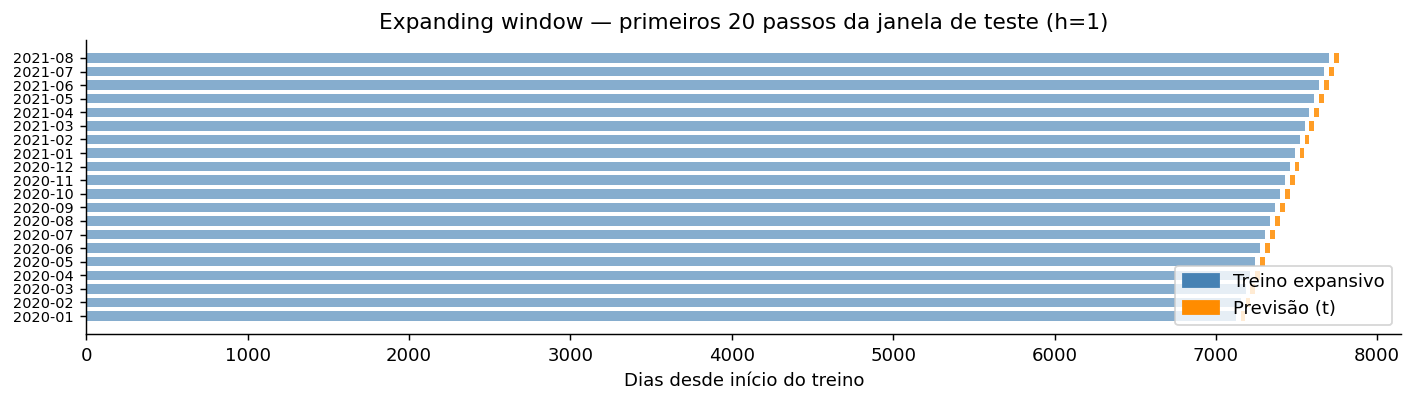

In [12]:
TRAIN_END = '2019-12-01'

train = df[df.index <= TRAIN_END]
test  = df[df.index >  TRAIN_END]

print(f'Treino: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} obs)')
print(f'Teste:  {test.index[0].date()}  → {test.index[-1].date()}  ({len(test)} obs)')

# Esquema visual da validação expansiva
fig, ax = plt.subplots(figsize=(11, 3.2))

n_test    = len(test)
n_show    = min(n_test, 20)  # mostra os primeiros 20 passos
fold_dates = test.index[:n_show]
train_starts = [train.index[0]] * n_show

for i, t in enumerate(fold_dates):
    train_end_i = t - pd.DateOffset(months=1)
    ax.barh(i,
            (train_end_i - train.index[0]).days,
            left=0,
            color='steelblue', alpha=0.65, height=0.7)
    ax.barh(i, 30, left=(t - train.index[0]).days,
            color='darkorange', alpha=0.85, height=0.7)

ax.set_yticks(range(n_show))
ax.set_yticklabels([d.strftime('%Y-%m') for d in fold_dates], fontsize=8)
ax.set_xlabel('Dias desde início do treino')
ax.set_title('Expanding window — primeiros 20 passos da janela de teste (h=1)')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='steelblue',  label='Treino expansivo'),
    Patch(color='darkorange', label='Previsão (t)'),
], loc='lower right')

plt.tight_layout()
plt.savefig('validacao_expanding_window.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Seleção da ordem ARIMAX via AIC/BIC

Busca em grade sobre `p ∈ {0,1,2}` e `q ∈ {0,1,2}` com `d = 0` (confirmado em 2.4).
Estimação sobre a janela de treino apenas.


In [13]:
exog_train = train[['usd_brl_lag4', 'us_cpi_lag2']]

grid_results = []
for p, q in itertools.product(range(3), range(3)):
    try:
        res = SARIMAX(
            train['ipca_pct'],
            exog=exog_train,
            order=(p, 0, q),
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False)
        grid_results.append({'p': p, 'q': q, 'aic': res.aic, 'bic': res.bic})
    except Exception:
        pass

grid_df = pd.DataFrame(grid_results).sort_values('aic')
print('Top 5 especificações por AIC:')
print(grid_df.head(5).round(2).to_string(index=False))

best_p = int(grid_df.iloc[0]['p'])
best_q = int(grid_df.iloc[0]['q'])
print(f'\n→ Ordem selecionada: ARIMAX({best_p}, 0, {best_q})')

Top 5 especificações por AIC:
 p  q   aic    bic
 2  2 69.33  93.46
 1  2 81.61 102.29
 2  1 91.09 111.80
 2  0 97.22 114.47
 1  1 97.25 114.51

→ Ordem selecionada: ARIMAX(2, 0, 2)


/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


### 6.1. Análise de sensibilidade — ordens adjacentes (p±1, q±1)

In [14]:
# Avalia desempenho fora da amostra no primeiro ano do teste (2020) para
# ordens vizinhas, antes de fixar a especificação.

def fit_predict_2020(p, q, exog_cols):
    test_2020 = df[(df.index >= '2020-01-01') & (df.index <= '2020-12-01')]
    preds, actuals = [], []
    for t in test_2020.index:
        train_w = df[df.index < t]
        try:
            res = SARIMAX(
                train_w['ipca_pct'],
                exog=train_w[exog_cols],
                order=(p, 0, q),
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False)
            fc = res.forecast(steps=1, exog=df.loc[[t], exog_cols])
            preds.append(fc.iloc[0])
            actuals.append(df.loc[t, 'ipca_pct'])
        except Exception:
            continue
    return mean_absolute_error(actuals, preds) if preds else np.nan


adj_p = sorted({max(0, best_p - 1), best_p, best_p + 1})
adj_q = sorted({max(0, best_q - 1), best_q, best_q + 1})

sens = []
for p in adj_p:
    for q in adj_q:
        mae_2020 = fit_predict_2020(p, q, ['usd_brl_lag4', 'us_cpi_lag2'])
        sens.append({'p': p, 'q': q, 'mae_2020': mae_2020})

sens_df = pd.DataFrame(sens).sort_values('mae_2020')
print('Sensibilidade — MAE no primeiro ano do teste (2020):')
print(sens_df.round(4).to_string(index=False))

P, D, Q = best_p, 0, best_q
print(f'\n→ Ordem fixada para a expanding window: ARIMAX({P}, {D}, {Q})')

/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: M

Sensibilidade — MAE no primeiro ano do teste (2020):
 p  q  mae_2020
 1  1    0.3086
 2  1    0.3098
 3  2    0.3304
 3  1    0.3310
 2  2    0.3317
 1  3    0.3622
 2  3    0.3647
 1  2    0.3834
 3  3    0.3965

→ Ordem fixada para a expanding window: ARIMAX(2, 0, 2)


/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 7. Estimação dos modelos sobre o treino

Três especificações para teste de H3 (contribuição incremental do CPI):
- **M1**: câmbio apenas
- **M2**: câmbio + CPI lag 2
- **M2b**: câmbio + CPI lag 3


In [15]:
def fit_arimax(endog, exog, order):
    return SARIMAX(
        endog,
        exog=exog,
        order=order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)


m1  = fit_arimax(train['ipca_pct'], train[['usd_brl_lag4']],                (P, D, Q))
m2  = fit_arimax(train['ipca_pct'], train[['usd_brl_lag4', 'us_cpi_lag2']], (P, D, Q))
m2b = fit_arimax(train['ipca_pct'], train[['usd_brl_lag4', 'us_cpi_lag3']], (P, D, Q))

print('M1 (só câmbio) — summary:')
print(m1.summary())
print('\n' + '='*70)
print('M2 (câmbio + CPI lag 2) — summary:')
print(m2.summary())

/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


M1 (só câmbio) — summary:
                               SARIMAX Results                                
Dep. Variable:               ipca_pct   No. Observations:                  235
Model:               SARIMAX(2, 0, 2)   Log Likelihood                 -28.898
Date:                Sat, 30 May 2026   AIC                             69.795
Time:                        08:52:59   BIC                             90.476
Sample:                    06-01-2000   HQIC                            78.136
                         - 12-01-2019                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
usd_brl_lag4     0.0118      0.003      4.020      0.000       0.006       0.018
ar.L1            1.4899      0.089     16.758      0.000       1.316       1.664
ar.L2           -0

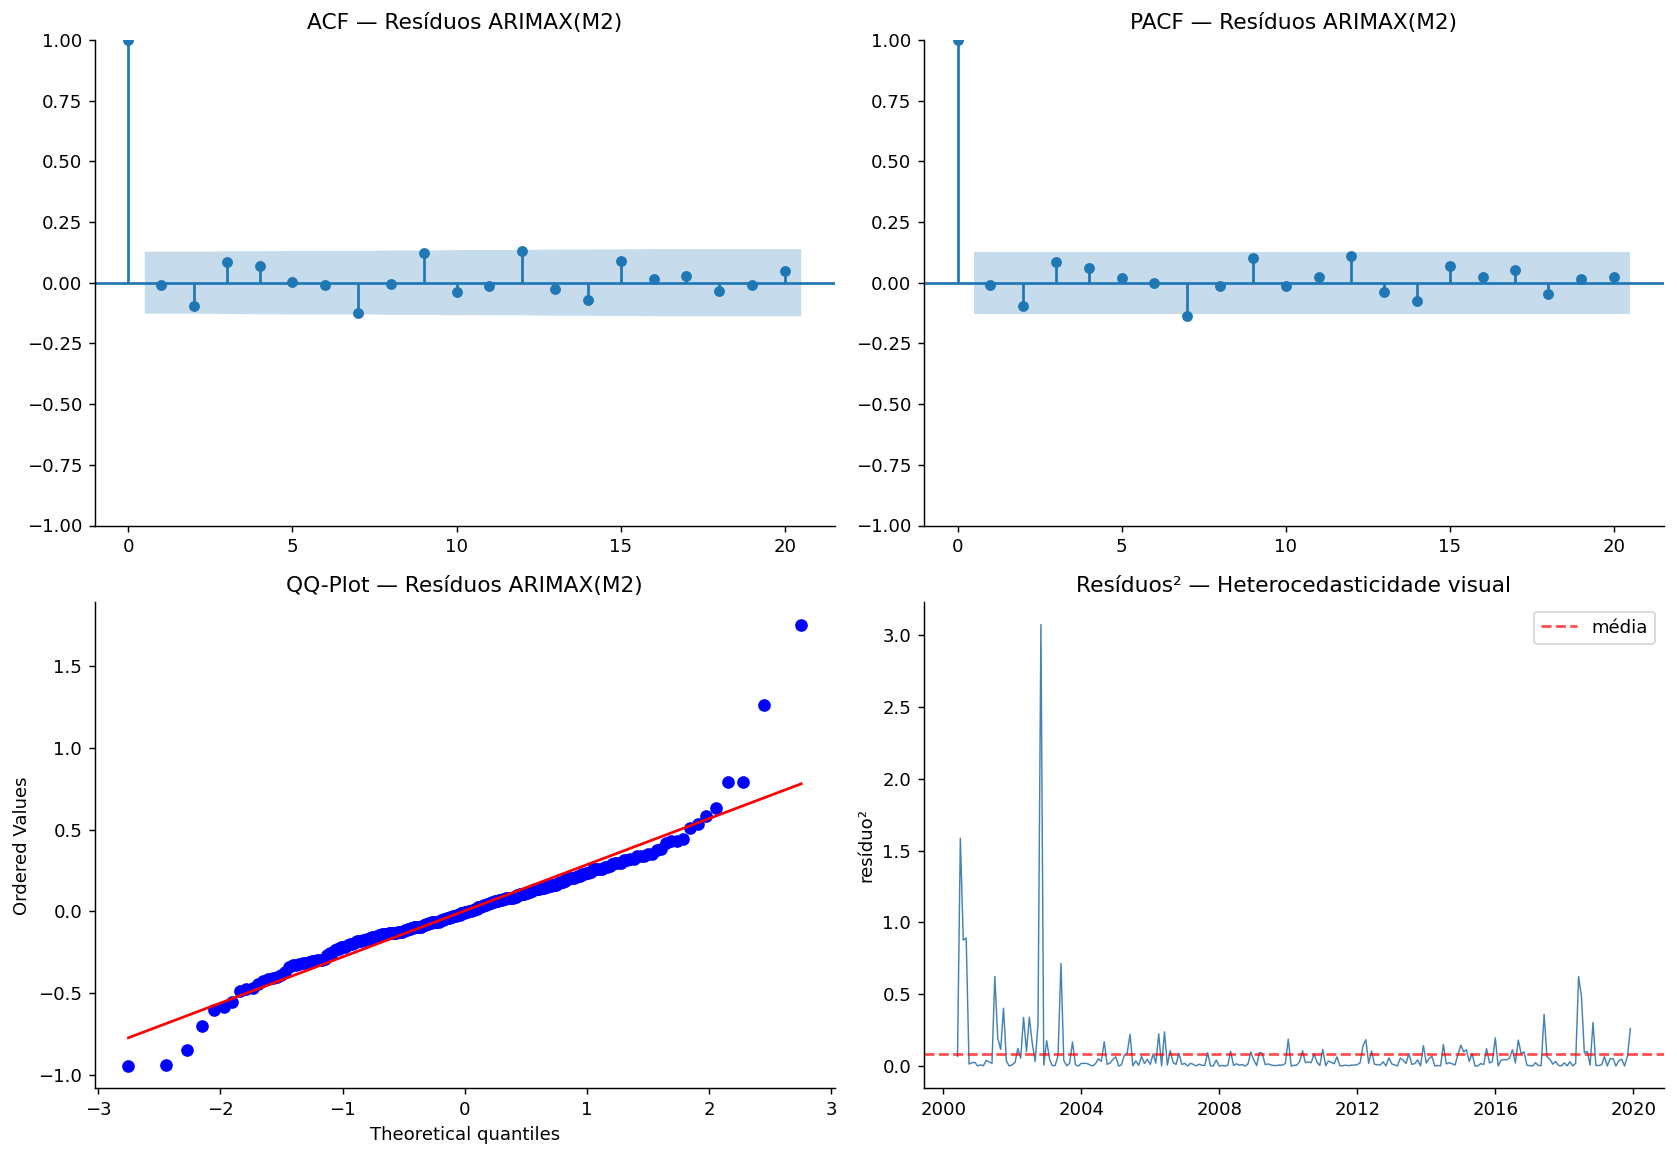

DIAGNÓSTICO DE RESÍDUOS — ARIMAX M2

── Ljung-Box (H₀: resíduos são ruído branco) ──
      lb_stat  lb_pvalue
10  12.881460   0.230375
20  21.790386   0.351992
  lag 10: p = 0.2304 → NÃO REJEITA H₀ (adequado)
  lag 20: p = 0.3520 → NÃO REJEITA H₀ (adequado)

── Jarque-Bera (H₀: resíduos normais) ──
  JB = 470.38, p = 0.0000
  → REJEITA H₀ (resíduos não-normais)
  Assimetria: 0.927
  Curtose:    6.679

── ARCH-LM, 5 lags (H₀: sem efeitos ARCH) ──
  LM = 1.98, p = 0.8521
  → NÃO REJEITA H₀ (homocedástico)

── RESUMO PARA TABELA ──
Ljung-Box(10): stat=12.88, p=0.2304
Ljung-Box(20): stat=21.79, p=0.3520
Jarque-Bera:   stat=470.38, p=0.0000
ARCH-LM(5):    stat=1.98, p=0.8521


In [16]:
# == 7b. Diagnóstico de resíduos do ARIMAX (M2: câmbio + CPI lag 2) ==

from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy import stats

resid = m2.resid

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# ACF resíduos
plot_acf(resid, lags=20, ax=axes[0, 0], title='ACF — Resíduos ARIMAX(M2)')

# PACF resíduos
plot_pacf(resid, lags=20, ax=axes[0, 1], method='ywm', title='PACF — Resíduos ARIMAX(M2)')

# QQ-plot (normalidade visual)
stats.probplot(resid, dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('QQ-Plot — Resíduos ARIMAX(M2)')

# Resíduos² (heterocedasticidade visual)
axes[1, 1].plot(resid.index, resid**2, color='steelblue', linewidth=0.8)
axes[1, 1].set_title('Resíduos² — Heterocedasticidade visual')
axes[1, 1].set_ylabel('resíduo²')
axes[1, 1].axhline(y=np.mean(resid**2), color='red', linestyle='--', alpha=0.7, label='média')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('arimax_residual_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Testes formais ──
print('=' * 60)
print('DIAGNÓSTICO DE RESÍDUOS — ARIMAX M2')
print('=' * 60)

# Ljung-Box (lags 10 e 20)
lb = acorr_ljungbox(resid, lags=[10, 20], return_df=True)
print('\n── Ljung-Box (H₀: resíduos são ruído branco) ──')
print(lb.to_string())
for _, row in lb.iterrows():
    status = 'NÃO REJEITA H₀ (adequado)' if row['lb_pvalue'] > 0.05 else 'REJEITA H₀ (autocorrelação residual)'
    print(f'  lag {int(row.name):2d}: p = {row["lb_pvalue"]:.4f} → {status}')

# Jarque-Bera (normalidade)
jb_stat, jb_p = stats.jarque_bera(resid)
print(f'\n── Jarque-Bera (H₀: resíduos normais) ──')
print(f'  JB = {jb_stat:.2f}, p = {jb_p:.4f}')
print(f'  → {"NÃO REJEITA H₀" if jb_p > 0.05 else "REJEITA H₀ (resíduos não-normais)"}')
print(f'  Assimetria: {stats.skew(resid):.3f}')
print(f'  Curtose:    {stats.kurtosis(resid, fisher=True):.3f}')

# ARCH-LM (heterocedasticidade condicional)
arch_stat, arch_p, _, _ = het_arch(resid, nlags=5)
print(f'\n── ARCH-LM, 5 lags (H₀: sem efeitos ARCH) ──')
print(f'  LM = {arch_stat:.2f}, p = {arch_p:.4f}')
print(f'  → {"NÃO REJEITA H₀ (homocedástico)" if arch_p > 0.05 else "REJEITA H₀ (efeitos ARCH presentes)"}')

# Resumo para tabela do TCC
print('\n── RESUMO PARA TABELA ──')
print(f'Ljung-Box(10): stat={lb.iloc[0]["lb_stat"]:.2f}, p={lb.iloc[0]["lb_pvalue"]:.4f}')
print(f'Ljung-Box(20): stat={lb.iloc[1]["lb_stat"]:.2f}, p={lb.iloc[1]["lb_pvalue"]:.4f}')
print(f'Jarque-Bera:   stat={jb_stat:.2f}, p={jb_p:.4f}')
print(f'ARCH-LM(5):    stat={arch_stat:.2f}, p={arch_p:.4f}')

## 8. Avaliação fora da amostra — expanding window (h = 1, 2, 3)

Para cada `t` no teste e cada horizonte `h`, o modelo é reestimado com todos os
dados até `t-h` e produz previsão direta para `t`.

**Observação metodológica:** para `h ≥ 3` com `us_cpi_lag2`, a feature não está
disponível no momento da previsão. A implementação abaixo restringe a especificação
M2 ao CPI lag 3 para `h = 3`, e mantém lag 2 para `h = 1, 2`.


In [17]:
def mase(actual, predicted, train_actual):
    """Mean Absolute Scaled Error: normaliza pelo erro do modelo naive de treino."""
    naive_mae = np.mean(np.abs(np.diff(train_actual)))
    return np.mean(np.abs(actual - predicted)) / naive_mae


def expanding_window_arimax(df, exog_cols, order, horizon, target='ipca_pct',
                             train_end=TRAIN_END, min_train=36):
    test_idx       = df[df.index > train_end].index
    preds, actuals, dates = [], [], []

    for t in test_idx:
        cutoff   = t - pd.DateOffset(months=horizon)
        train_w  = df[df.index <= cutoff]

        if len(train_w) < min_train:
            continue

        try:
            res = fit_arimax(train_w[target], train_w[exog_cols], order)
            # Previsão direta: horizonte h, retornamos o último valor
            exog_future = df.loc[cutoff + pd.DateOffset(months=1):t, exog_cols]
            if len(exog_future) < horizon:
                preds.append(np.nan)
            else:
                fc = res.forecast(steps=horizon, exog=exog_future)
                preds.append(fc.iloc[-1])
        except Exception:
            preds.append(np.nan)

        actuals.append(df.loc[t, target])
        dates.append(t)

    return np.array(actuals), np.array(preds), pd.DatetimeIndex(dates)


# Especificações por horizonte (CPI lag 2 só viável para h<=2)
specs = {
    'M1_fx':      ['usd_brl_lag4'],
    'M2_fx_cpi2': ['usd_brl_lag4', 'us_cpi_lag2'],
    'M2_fx_cpi3': ['usd_brl_lag4', 'us_cpi_lag3'],
}

print('Iniciando expanding window (pode demorar alguns minutos)...')
results_ew = {}

for h in [1, 2, 3]:
    for name, exog_cols in specs.items():
        # CPI lag 2 inviável para h > 2 (feature indisponível)
        if name == 'M2_fx_cpi2' and h > 2:
            continue
        act, pred, dates = expanding_window_arimax(
            df, exog_cols, (P, D, Q), horizon=h
        )
        results_ew[(name, h)] = {
            'actuals': act,
            'preds':   pred,
            'dates':   dates,
        }
        print(f'  h={h} | {name} ✓  ({(~np.isnan(pred)).sum()} previsões)')

print('Expanding window concluída.')

Iniciando expanding window (pode demorar alguns minutos)...


/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: M

  h=1 | M1_fx ✓  (60 previsões)


/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: M

  h=1 | M2_fx_cpi2 ✓  (60 previsões)


...

/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: M

  h=3 | M1_fx ✓  (60 previsões)


/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: M

  h=3 | M2_fx_cpi3 ✓  (60 previsões)
Expanding window concluída.


/opt/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 9. Métricas de avaliação — período completo de teste

Atende ao tópico 6 dos resultados preliminares: primeiras métricas (MAE, RMSE,
MASE) e tabela comparativa.


In [18]:
train_ipca = df[df.index <= TRAIN_END]['ipca_pct'].values

rows = []
for (name, h), d in results_ew.items():
    act, pred = d['actuals'], d['preds']
    mask      = ~np.isnan(pred)
    rows.append({
        'model':   name,
        'horizon': h,
        'MAE':     mean_absolute_error(act[mask], pred[mask]),
        'RMSE':    np.sqrt(mean_squared_error(act[mask], pred[mask])),
        'MASE':    mase(act[mask], pred[mask], train_ipca),
        'n':       int(mask.sum()),
    })

metrics_df = pd.DataFrame(rows).sort_values(['horizon', 'MAE'])
print('Métricas ARIMAX — período completo (jan/2020–dez/2024):')
print(metrics_df.round(4).to_string(index=False))

Métricas ARIMAX — período completo (jan/2020–dez/2024):
     model  horizon    MAE   RMSE   MASE  n
M2_fx_cpi3        1 0.2913 0.3784 1.2550 60
     M1_fx        1 0.2915 0.3797 1.2555 60
M2_fx_cpi2        1 0.2920 0.3804 1.2579 60
     M1_fx        2 0.3176 0.4209 1.3681 60
M2_fx_cpi3        2 0.3179 0.4221 1.3695 60
M2_fx_cpi2        2 0.3187 0.4298 1.3729 60
M2_fx_cpi3        3 0.3386 0.4597 1.4587 60
     M1_fx        3 0.3388 0.4582 1.4594 60


### 9.1. Métricas por subperíodo (choque agudo 2020-21 vs. acomodação 2022-24)

In [19]:
rows_sub = []
for (name, h), d in results_ew.items():
    mask_v   = ~np.isnan(d['preds'])
    dates    = d['dates'][mask_v]
    act_v    = d['actuals'][mask_v]
    pred_v   = d['preds'][mask_v]

    for label, start, end in [
        ('choque_2020_2021',  '2020-01-01', '2021-12-31'),
        ('acomodacao_22_24',  '2022-01-01', '2024-12-31'),
    ]:
        m_sub = (dates >= start) & (dates <= end)
        if m_sub.sum() < 3:
            continue
        rows_sub.append({
            'model':     name,
            'horizon':   h,
            'subperiod': label,
            'MAE':       mean_absolute_error(act_v[m_sub], pred_v[m_sub]),
            'RMSE':      np.sqrt(mean_squared_error(act_v[m_sub], pred_v[m_sub])),
            'n':         int(m_sub.sum()),
        })

subperiod_df = pd.DataFrame(rows_sub).sort_values(['horizon', 'subperiod', 'MAE'])
print('Métricas por subperíodo:')
print(subperiod_df.round(4).to_string(index=False))

Métricas por subperíodo:
     model  horizon        subperiod    MAE   RMSE  n
M2_fx_cpi2        1 acomodacao_22_24 0.2470 0.3561 36
M2_fx_cpi3        1 acomodacao_22_24 0.2497 0.3617 36
     M1_fx        1 acomodacao_22_24 0.2502 0.3607 36
     M1_fx        1 choque_2020_2021 0.3533 0.4064 24
M2_fx_cpi3        1 choque_2020_2021 0.3538 0.4022 24
M2_fx_cpi2        1 choque_2020_2021 0.3596 0.4141 24
M2_fx_cpi2        2 acomodacao_22_24 0.2740 0.4119 36
M2_fx_cpi3        2 acomodacao_22_24 0.2774 0.4047 36
     M1_fx        2 acomodacao_22_24 0.2796 0.4058 36
     M1_fx        2 choque_2020_2021 0.3745 0.4427 24
M2_fx_cpi3        2 choque_2020_2021 0.3786 0.4470 24
M2_fx_cpi2        2 choque_2020_2021 0.3858 0.4554 24
M2_fx_cpi3        3 acomodacao_22_24 0.3000 0.4428 36
     M1_fx        3 acomodacao_22_24 0.3023 0.4437 36
     M1_fx        3 choque_2020_2021 0.3935 0.4792 24
M2_fx_cpi3        3 choque_2020_2021 0.3966 0.4840 24


## 10. Análise por regime de volatilidade cambial (H2)

Volatilidade mensurada pelo desvio padrão móvel de 12 meses do `usd_brl_pct`.
Limiar: mediana sobre janela de treino (fixo para teste, evita contaminação).


In [20]:
df['vol_cambio_12m'] = df['usd_brl_pct'].rolling(12).std()

vol_threshold = df[df.index <= TRAIN_END]['vol_cambio_12m'].median()
print(f'Limiar de volatilidade (mediana sobre treino): {vol_threshold:.4f}')

df['regime_vol'] = np.where(df['vol_cambio_12m'] > vol_threshold, 'alta', 'baixa')

dist_test = df[df.index > TRAIN_END]['regime_vol'].value_counts()
print(f'\nDistribuição do regime no teste:\n{dist_test}')

Limiar de volatilidade (mediana sobre treino): 4.0499

Distribuição do regime no teste:
regime_vol
alta     33
baixa    27
Name: count, dtype: int64


In [21]:
rows_regime = []
for (name, h), d in results_ew.items():
    mask_v   = ~np.isnan(d['preds'])
    dates    = d['dates'][mask_v]
    act_v    = d['actuals'][mask_v]
    pred_v   = d['preds'][mask_v]

    regimes = df.loc[dates, 'regime_vol'].values

    for regime in ['alta', 'baixa']:
        m_reg = regimes == regime
        if m_reg.sum() < 3:
            continue
        rows_regime.append({
            'model':   name,
            'horizon': h,
            'regime':  regime,
            'MAE':     mean_absolute_error(act_v[m_reg], pred_v[m_reg]),
            'RMSE':    np.sqrt(mean_squared_error(act_v[m_reg], pred_v[m_reg])),
            'n':       int(m_reg.sum()),
        })

regime_df = pd.DataFrame(rows_regime).sort_values(['horizon', 'regime', 'MAE'])
print('Métricas por regime de volatilidade:')
print(regime_df.round(4).to_string(index=False))

Métricas por regime de volatilidade:
     model  horizon regime    MAE   RMSE  n
M2_fx_cpi2        1   alta 0.3587 0.4401 33
M2_fx_cpi3        1   alta 0.3635 0.4403 33
     M1_fx        1   alta 0.3639 0.4421 33
     M1_fx        1  baixa 0.2029 0.2853 27
M2_fx_cpi3        1  baixa 0.2031 0.2852 27
M2_fx_cpi2        1  baixa 0.2105 0.2912 27
     M1_fx        2   alta 0.3972 0.4809 33
M2_fx_cpi3        2   alta 0.3988 0.4828 33
M2_fx_cpi2        2   alta 0.4013 0.4914 33
M2_fx_cpi2        2  baixa 0.2178 0.3398 27
M2_fx_cpi3        2  baixa 0.2191 0.3333 27
     M1_fx        2  baixa 0.2202 0.3332 27
M2_fx_cpi3        3   alta 0.4218 0.5377 33
     M1_fx        3   alta 0.4218 0.5356 33
M2_fx_cpi3        3  baixa 0.2369 0.3409 27
     M1_fx        3  baixa 0.2373 0.3406 27


## 11. Teste de Diebold-Mariano — H3 (ganho do CPI)

H₀: M1 (só câmbio) e M2 (câmbio + CPI) têm acurácia equivalente.
Variância HAC com Newey-West (lags = h-1).


In [22]:
def diebold_mariano(e1, e2, h=1):
    d      = e1**2 - e2**2
    n      = len(d)
    d_mean = np.mean(d)

    gamma0 = np.var(d, ddof=1)
    gammas = [np.cov(d[k:], d[:-k])[0, 1] for k in range(1, h)] if h > 1 else []
    var_d  = max((gamma0 + 2 * sum(gammas)) / n, 1e-10)

    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))

    return {'dm_stat': dm_stat, 'p_value': p_value}


print('Teste Diebold-Mariano — M1 (só câmbio) vs M2 (câmbio + CPI)')
print('DM < 0 → M2 melhor | p < 0.05 → rejeita H0')
print('-' * 75)

dm_rows = []
for h in [1, 2, 3]:
    m1_d = results_ew.get(('M1_fx', h))
    # Para h<=2 usa lag 2; para h=3 usa lag 3
    cpi_spec = 'M2_fx_cpi2' if h <= 2 else 'M2_fx_cpi3'
    m2_d = results_ew.get((cpi_spec, h))

    if not m1_d or not m2_d:
        continue

    act  = m1_d['actuals']
    e1   = act - m1_d['preds']
    e2   = act - m2_d['preds']
    mask = ~(np.isnan(e1) | np.isnan(e2))

    dm = diebold_mariano(e1[mask], e2[mask], h=h)
    sig = '✓ SIGNIFICATIVO (5%)' if dm['p_value'] < 0.05 else '✗ não significativo'
    print(f'  h={h} ({cpi_spec}): DM={dm["dm_stat"]:+.4f}, p={dm["p_value"]:.4f} → {sig}')

    dm_rows.append({
        'horizon':   h,
        'spec':      f'M1 vs {cpi_spec}',
        'dm_stat':   dm['dm_stat'],
        'p_value':   dm['p_value'],
        'significant_5pct': dm['p_value'] < 0.05,
    })

dm_df = pd.DataFrame(dm_rows)

Teste Diebold-Mariano — M1 (só câmbio) vs M2 (câmbio + CPI)
DM < 0 → M2 melhor | p < 0.05 → rejeita H0
---------------------------------------------------------------------------
  h=1 (M2_fx_cpi2): DM=-0.1732, p=0.8625 → ✗ não significativo
  h=2 (M2_fx_cpi2): DM=-1.7413, p=0.0816 → ✗ não significativo
  h=3 (M2_fx_cpi3): DM=-0.4949, p=0.6207 → ✗ não significativo


## 12. Visualizações — observado vs. previsto

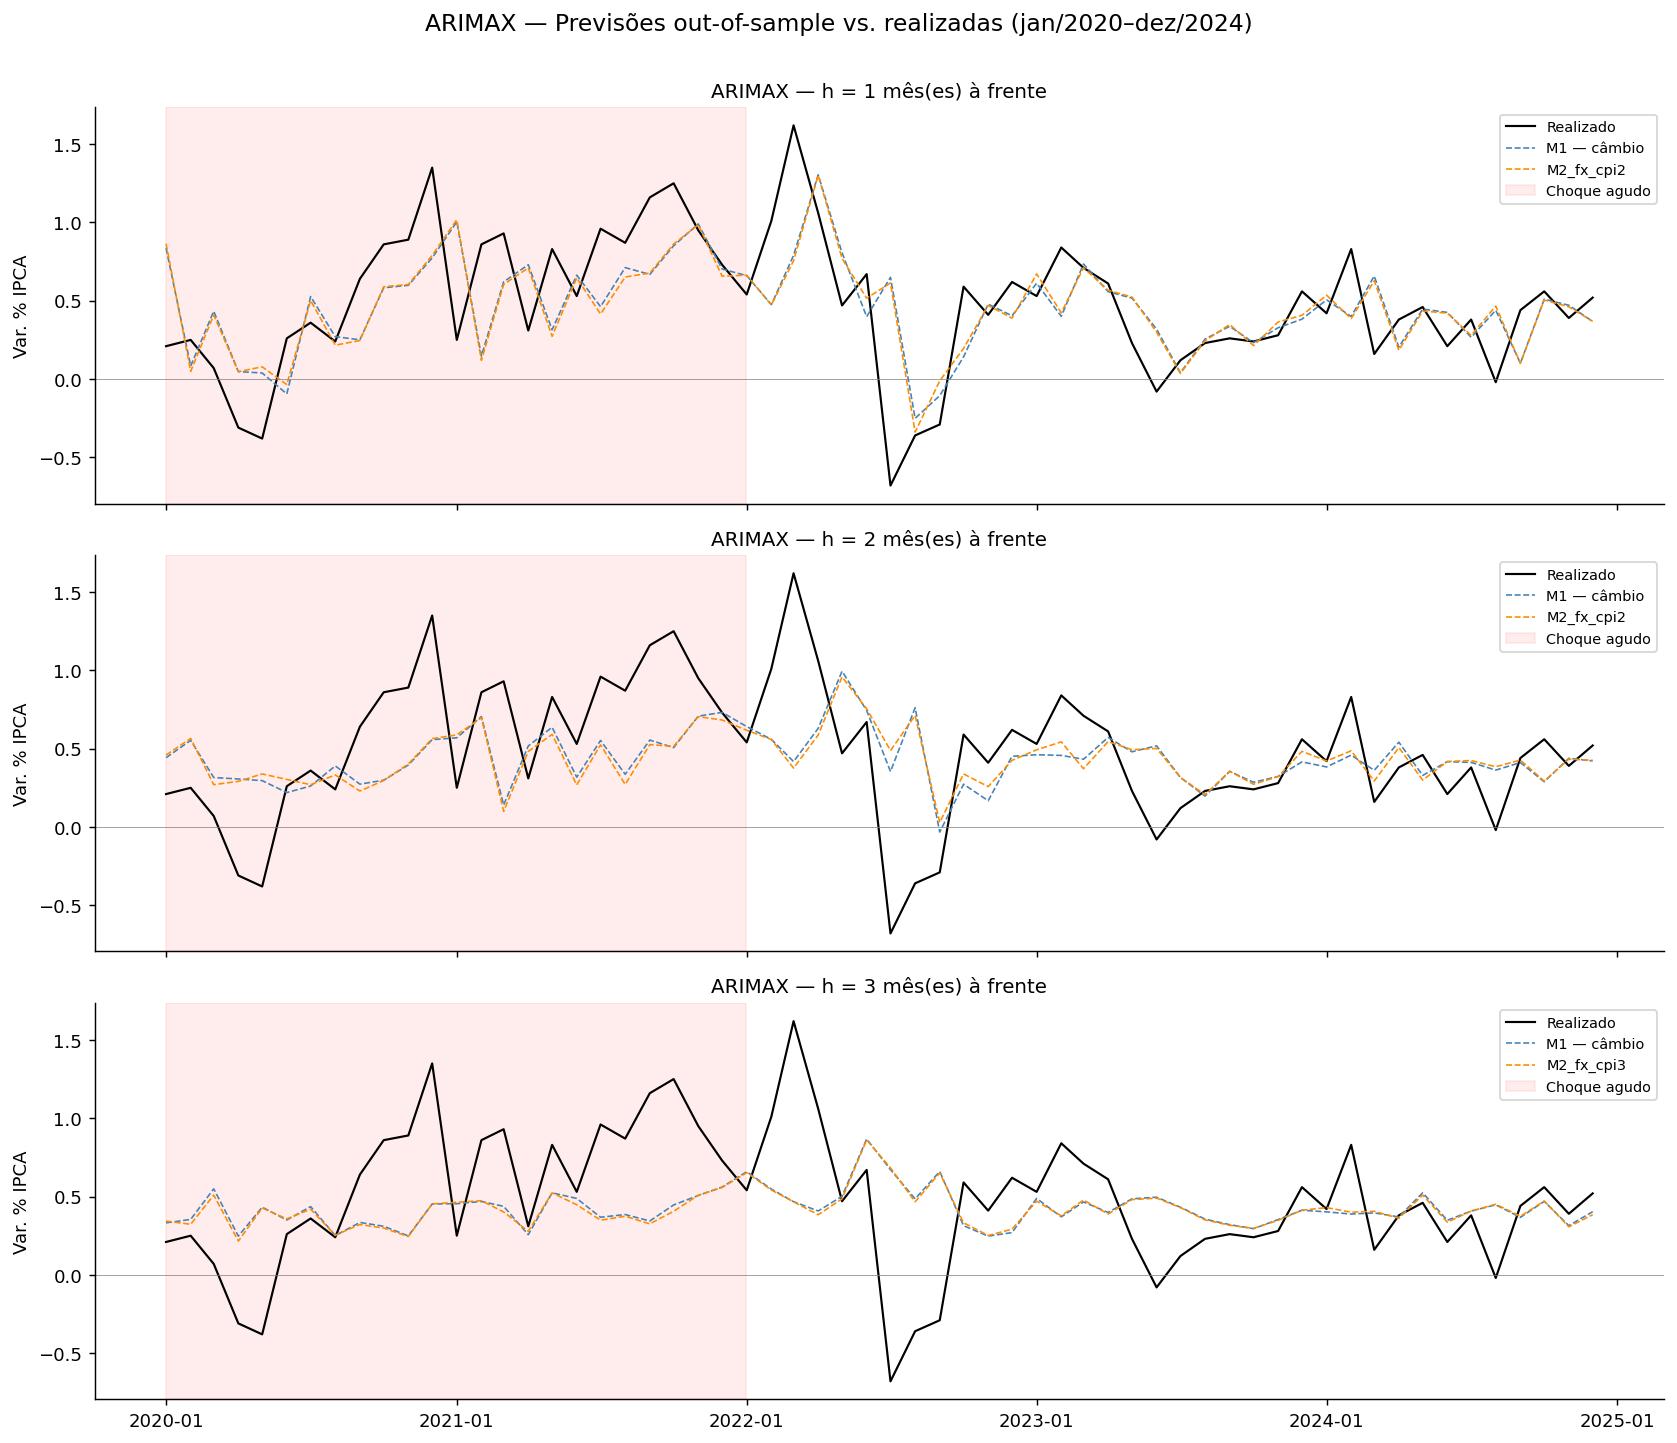

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

for i, h in enumerate([1, 2, 3]):
    ax       = axes[i]
    d_m1     = results_ew[('M1_fx', h)]
    cpi_spec = 'M2_fx_cpi2' if h <= 2 else 'M2_fx_cpi3'
    d_m2     = results_ew[(cpi_spec, h)]

    ax.plot(d_m1['dates'], d_m1['actuals'], color='black',     linewidth=1.2, label='Realizado')
    ax.plot(d_m1['dates'], d_m1['preds'],   color='steelblue', linewidth=0.9,
            linestyle='--', label='M1 — câmbio')
    ax.plot(d_m2['dates'], d_m2['preds'],   color='darkorange', linewidth=0.9,
            linestyle='--', label=f'{cpi_spec}')

    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-31'),
               alpha=0.07, color='red', label='Choque agudo')
    ax.axhline(0, color='gray', linewidth=0.4)
    ax.set_title(f'ARIMAX — h = {h} mês(es) à frente', fontsize=11)
    ax.set_ylabel('Var. % IPCA')
    ax.legend(fontsize=8, loc='upper right')

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.suptitle('ARIMAX — Previsões out-of-sample vs. realizadas (jan/2020–dez/2024)',
             fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig('arimax_ew_forecasts.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Exportação dos resultados

In [24]:
# Modelos estimados sobre toda a janela de treino
with open('arimax_m1.pkl',  'wb') as f: pickle.dump(m1,  f)
with open('arimax_m2.pkl',  'wb') as f: pickle.dump(m2,  f)
with open('arimax_m2b.pkl', 'wb') as f: pickle.dump(m2b, f)

# Métricas
metrics_df.to_csv('arimax_metrics.csv',           index=False)
subperiod_df.to_csv('arimax_metrics_subperiod.csv', index=False)
regime_df.to_csv('arimax_metrics_regime.csv',     index=False)
dm_df.to_csv('arimax_dm_test.csv',                index=False)
stationarity_df.to_csv('arimax_stationarity.csv', index=False)

# Previsões fora da amostra
for (name, h), d in results_ew.items():
    pd.DataFrame({
        'date':      d['dates'],
        'actual':    d['actuals'],
        'predicted': d['preds'],
    }).to_csv(f'arimax_preds_{name}_h{h}.csv', index=False)

print('Exportação concluída.')

Exportação concluída.
